In [23]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import os
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/Proyecto-neumonia') # Especificar la ruta de la carpeta de tu Drive donde debe estar previamente el notebook 01_eda_y_preprocesado.ipynb
# DESCOMENTAR SOLO SI SE QUIERE DESCARGAR EL CONJUNTO DE DATOS ORIGINAL DE KAGGLE
if not os.path.exists('dataset'):
  os.environ['KAGGLE_API_TOKEN'] = 'TOKEN_KAGGLE' # Sustituir por tu token de Kaggle
  !kaggle datasets download -d gonzajl/neumona-x-rays-dataset
  !unzip -o neumona-x-rays-dataset.zip -d dataset/
else:
  print('La carpeta dataset ya existe')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
La carpeta dataset ya existe


In [24]:
#@title Redimensionado de las imágenes del dataset
IMG_DIM = (180, 180) # Dimensión que se tomará para las imágenes
DATA_PATH = "./dataset/dataset"   # Ruta donde se guardan las imágenes
CATEGORIAS = ["no-neumonia", "neumonia"]   # Categorización de las imágenes

def cargar_y_preprocesar(ruta_base):
  datos = []
  etiquetas = []
  for id_clase, categoria in enumerate(CATEGORIAS):  # Recorremos las categorías anteriores
    ruta_categoria = os.path.join(ruta_base, categoria) # Cargamos la ruta a la carpeta con las imágenes de dicha categoría

    for nombre_img in os.listdir(ruta_categoria):  # Recorremos cada imagen de la categoría
      ruta_img = os.path.join(ruta_categoria, nombre_img)   # Extraemos su ruta
      try:
        img_array = cv.imread(ruta_img,0) # Leer imagen en escala de grises de 8 bits
        if img_array is not None:  # Si la imagen existe o no da error
          img_redim = cv.resize(img_array, IMG_DIM) # Redimensionar la imagen a 180x180
          img_norm = img_redim.astype('float32')/255.0 # Normalizar los píxeles de la imagen para trabajar en el rango [0,1] y agilizar los cálculos
          datos.append(img_norm) # Añadimos la imagen a la lista de datos
          etiquetas.append(id_clase) # Añadimos su categoría a la lista de datos
      except Exception as e: # Si hay un error, imprimirlo
        print(e)
        pass
  return np.array(datos), np.array(etiquetas)  # Devolvemos dos arrays, uno con las imágenes preprocesadas y otro con las etiquetas referente a esos datos

In [25]:
X, y = cargar_y_preprocesar(DATA_PATH)  # Aplicamos el preprocesado a las imágenes
print(f'Número de imágenes cargadas: {len(X)}')

Número de imágenes cargadas: 10498


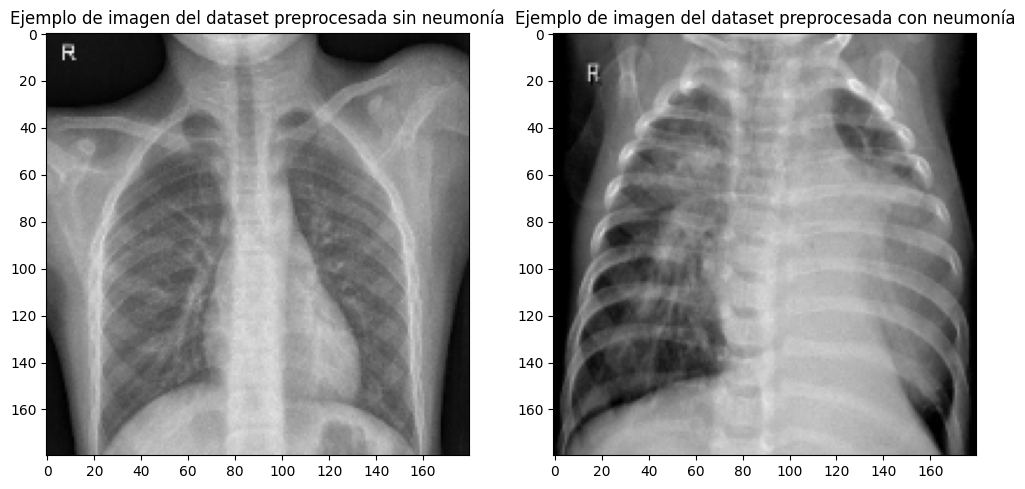

In [26]:
# Imprimimos por pantalla una muestra de imágenes preprocesadas, una de cada categoría

plt.figure(figsize=(12, 10))
plt.subplot(1,2,1)
plt.title('Ejemplo de imagen del dataset preprocesada sin neumonía')
plt.imshow(X[9], cmap='gray', vmin=0, vmax=1)

plt.subplot(1,2,2)
plt.title('Ejemplo de imagen del dataset preprocesada con neumonía')
plt.imshow(X[6000], cmap='gray', vmin=0, vmax=1)

In [27]:


#@title División del dataset en entrenamiento, validación y pruebas
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=230406, stratify=y)

# Para dividir el 80% restante en entrenamiento y validación, tomamos el 18.75% para escoger aproximadamente el 15% del dataset original (0.8 * 0.1875 = 0.15)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1875, random_state=230406, stratify=y_temp)

In [28]:
#@title Ajuste para entrenamiento con CNNs en Keras/Tensorflow
# Las CNNs en Keras son estrictas con el formato de los datos que reciben, siempre deben recibir datos de 4 dimensiones (Número de imágenes, alto, ancho, canales).
# Como hemos preprocesado las imágenes en escala de grises, solo tienen 3 dimensiones (x, 180, 180) por lo que debemos agregar una cuarta dimensión extra -->
# (x, 180, 180, 1)
X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print(f'Dimensiones de los datos de entrenamiento: {X_train.shape}')
print(f'Dimensiones de los datos de validación: {X_val.shape}')
print(f'Dimensiones de los datos de prueba: {X_test.shape}')

Dimensiones de los datos de entrenamiento: (6823, 180, 180, 1)
Dimensiones de los datos de validación: (1575, 180, 180, 1)
Dimensiones de los datos de prueba: (2100, 180, 180, 1)


In [30]:
# Guardar los subconjuntos generados:
ruta = '/content/drive/MyDrive/Proyecto-neumonia' # Sustituir por la ruta de la carpeta en Drive
np.save(ruta + 'X_train.npy', X_train)
np.save(ruta + 'y_train.npy', y_train)
np.save(ruta + 'X_val.npy', X_val)
np.save(ruta + 'y_val.npy', y_val)
np.save(ruta + 'X_test.npy', X_test)
np.save(ruta + 'y_test.npy', y_test)